# 01b - Data Collection (Additional Cities)
Expands the dataset from 5 to 28 cities for the full training/validation/test design. Kiel, Leipzig, Dresden, Rostock and Munster were already collected in `01_data_collection.ipynb` and are not re-downloaded here. This notebook pulls the remaining 23 cities: Sentinel-1 (VV, VH) and ESA WorldCover labels, exported to the same Google Drive folder, then merges the metadata with the existing dataset index.

## Cell 1: Install packages
Installs the Earth Engine Python API and geemap, the same libraries used in the original data collection notebook.

In [1]:
!pip install earthengine-api geemap -q

## Cell 2: Authenticate and initialize Earth Engine
Connects to the same Earth Engine project used for the first 5 cities, so all exports land in one consistent dataset.

In [2]:
import ee

ee.Authenticate()
ee.Initialize(project='lulc-sentinel1')

## Cell 3: Define the 23 additional city bounding boxes
Kiel, Leipzig, Dresden, Rostock and Munster already exist in Drive from the first collection run, so they are intentionally left out here. The 23 new cities below cover the rest of the dataset design: more German training cities, climate-similar cities abroad used for training, a validation city, a same-region test city, two similar-but-unseen-region test cities, and three fully dissimilar-region test cities.

In [3]:
new_cities = {
    # Germany, training
    "Hamburg": ee.Geometry.Rectangle([9.8937, 53.4961, 10.0937, 53.6061]),
    "Berlin": ee.Geometry.Rectangle([13.3050, 52.4650, 13.5050, 52.5750]),
    "Munich": ee.Geometry.Rectangle([11.4820, 48.0801, 11.6820, 48.1901]),
    "Stuttgart": ee.Geometry.Rectangle([9.0829, 48.7208, 9.2829, 48.8308]),

    # Germany, validation and same-region test
    "Freiburg": ee.Geometry.Rectangle([7.7421, 47.9440, 7.9421, 48.0540]),
    "Bremen": ee.Geometry.Rectangle([8.7017, 53.0243, 8.9017, 53.1343]),

    # Climate-similar abroad, training
    "Portland": ee.Geometry.Rectangle([-122.7784, 45.4602, -122.5784, 45.5702]),
    "Toronto": ee.Geometry.Rectangle([-79.4470, 43.5961, -79.2470, 43.7061]),
    "Vancouver": ee.Geometry.Rectangle([-123.2207, 49.2277, -123.0207, 49.3377]),
    "Melbourne": ee.Geometry.Rectangle([144.8631, -37.8686, 145.0631, -37.7586]),
    "Vienna": ee.Geometry.Rectangle([16.2738, 48.1532, 16.4738, 48.2632]),
    "Zurich": ee.Geometry.Rectangle([8.4417, 47.3219, 8.6417, 47.4319]),
    "London": ee.Geometry.Rectangle([-0.2278, 51.4524, -0.0278, 51.5624]),
    "Amsterdam": ee.Geometry.Rectangle([4.8041, 52.3126, 5.0041, 52.4226]),
    "Brussels": ee.Geometry.Rectangle([4.2517, 50.7953, 4.4517, 50.9053]),
    "Copenhagen": ee.Geometry.Rectangle([12.4683, 55.6211, 12.6683, 55.7311]),
    "Warsaw": ee.Geometry.Rectangle([20.9122, 52.1747, 21.1122, 52.2847]),
    "Prague": ee.Geometry.Rectangle([14.3378, 50.0205, 14.5378, 50.1305]),

    # Similar-but-unseen-region test
    "CapeTown": ee.Geometry.Rectangle([18.3241, -33.9799, 18.5241, -33.8699]),
    "Christchurch": ee.Geometry.Rectangle([172.5362, -43.5871, 172.7362, -43.4771]),

    # Fully dissimilar-region test
    "Mumbai": ee.Geometry.Rectangle([72.7777, 19.0210, 72.9777, 19.1310]),
    "Lagos": ee.Geometry.Rectangle([3.2792, 6.4694, 3.4792, 6.5794]),
    "Cairo": ee.Geometry.Rectangle([31.1357, 29.9894, 31.3357, 30.0994]),
}

print(f"Total new cities to collect: {len(new_cities)}")
for name, geom in new_cities.items():
    print(name, geom.bounds().getInfo()['coordinates'])

Total new cities to collect: 23
Hamburg [[[9.893699999999999, 53.49609999999996], [10.0937, 53.49609999999996], [10.0937, 53.60614167914524], [9.893699999999999, 53.60614167914524], [9.893699999999999, 53.49609999999996]]]
Berlin [[[13.304999999999998, 52.46499999999998], [13.505000000000003, 52.46499999999998], [13.505000000000003, 52.57504211676837], [13.304999999999998, 52.57504211676837], [13.304999999999998, 52.46499999999998]]]
Munich [[[11.482, 48.08009999999998], [11.682000000000002, 48.08009999999998], [11.682000000000002, 48.19014336300209], [11.482, 48.19014336300209], [11.482, 48.08009999999998]]]
Stuttgart [[[9.0829, 48.720799999999976], [9.282900000000001, 48.720799999999976], [9.282900000000001, 48.83084324372528], [9.0829, 48.83084324372528], [9.0829, 48.720799999999976]]]
Freiburg [[[7.7421, 47.94399999999998], [7.9421, 47.94399999999998], [7.9421, 48.05404338554826], [7.7421, 48.05404338554826], [7.7421, 47.94399999999998]]]
Bremen [[[8.7017, 53.02429999999997], [8.90

## Cell 4: Land mix check per new city
Pulls real ESA WorldCover class percentages for each new city, the same way the original 5 cities were checked, so the dataset's regional and climate diversity can be described with real numbers rather than assumptions.

In [4]:
worldcover = ee.ImageCollection('ESA/WorldCover/v200').first()

class_names = {
    10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
    50: "Built-up", 60: "Bare/sparse vegetation", 70: "Snow/ice",
    80: "Permanent water", 90: "Herbaceous wetland", 95: "Mangroves", 100: "Moss/lichen"
}

new_city_land_mix = {}

for city, geom in new_cities.items():
    clipped = worldcover.clip(geom)
    hist = clipped.reduceRegion(
        reducer=ee.Reducer.frequencyHistogram(),
        geometry=geom,
        scale=100,
        maxPixels=1e9
    ).getInfo()

    counts = hist['Map']
    total = sum(counts.values())
    pct_by_class = {}

    print(f"\n=== {city} ===")
    sorted_classes = sorted(counts.items(), key=lambda x: -x[1])
    for code, count in sorted_classes:
        pct = (count / total) * 100
        name = class_names.get(int(float(code)), f"Unknown ({code})")
        pct_by_class[name] = round(pct, 1)
        print(f"{name}: {pct:.1f}%")

    new_city_land_mix[city] = pct_by_class


=== Hamburg ===
Built-up: 50.6%
Tree cover: 32.3%
Permanent water: 12.0%
Grassland: 4.5%
Cropland: 0.3%
Bare/sparse vegetation: 0.1%
Herbaceous wetland: 0.1%

=== Berlin ===
Built-up: 60.1%
Tree cover: 34.0%
Grassland: 3.5%
Permanent water: 1.9%
Cropland: 0.4%
Bare/sparse vegetation: 0.0%
Herbaceous wetland: 0.0%

=== Munich ===
Built-up: 48.7%
Tree cover: 40.1%
Cropland: 5.2%
Grassland: 5.1%
Permanent water: 0.7%
Bare/sparse vegetation: 0.2%

=== Stuttgart ===
Tree cover: 52.2%
Built-up: 33.0%
Grassland: 9.0%
Cropland: 4.9%
Permanent water: 0.8%
Bare/sparse vegetation: 0.0%

=== Freiburg ===
Tree cover: 60.3%
Grassland: 17.2%
Built-up: 16.2%
Cropland: 5.9%
Permanent water: 0.4%
Bare/sparse vegetation: 0.0%

=== Bremen ===
Tree cover: 35.0%
Built-up: 33.0%
Grassland: 23.6%
Permanent water: 5.5%
Cropland: 2.3%
Herbaceous wetland: 0.3%
Bare/sparse vegetation: 0.3%

=== Portland ===
Tree cover: 61.8%
Built-up: 31.5%
Permanent water: 4.2%
Grassland: 2.2%
Bare/sparse vegetation: 0.3%
Cropl

## Cell 5: Mount Google Drive
Uses the same export folder as the original collection run, so all 28 cities end up in one place.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_FOLDER = '/content/drive/MyDrive/lulc_dataset'
os.makedirs(DRIVE_FOLDER, exist_ok=True)
print("Export folder ready at:", DRIVE_FOLDER)

Mounted at /content/drive
Export folder ready at: /content/drive/MyDrive/lulc_dataset


## Cell 6: Define the Sentinel-1 + WorldCover pulling function
The same export function used for the first 5 cities: pulls one Sentinel-1 VV/VH monthly median composite and the WorldCover label for a given city and month, and starts an Earth Engine export task to Google Drive for each.

In [6]:
import calendar

def get_month_range(year, month):
    start = f"{year}-{month:02d}-01"
    last_day = calendar.monthrange(year, month)[1]
    end = f"{year}-{month:02d}-{last_day:02d}"
    return start, end

def export_city_month(city_name, geom, year, month):
    start, end = get_month_range(year, month)

    s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
        .filterBounds(geom) \
        .filterDate(start, end) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')) \
        .filter(ee.Filter.eq('instrumentMode', 'IW'))

    count = s1.size().getInfo()
    if count == 0:
        print(f"  [SKIP] {city_name} {year}-{month:02d}: no Sentinel-1 images found")
        return None

    s1_image = s1.median().select(['VV', 'VH']).clip(geom)
    worldcover_img = ee.ImageCollection('ESA/WorldCover/v200').first().clip(geom)

    tag = f"{city_name}_{year}_{month:02d}"

    s1_task = ee.batch.Export.image.toDrive(
        image=s1_image,
        description=f"s1_{tag}",
        folder='lulc_dataset',
        fileNamePrefix=f"s1_{tag}",
        region=geom,
        scale=10,
        maxPixels=1e9
    )
    s1_task.start()

    wc_task = ee.batch.Export.image.toDrive(
        image=worldcover_img,
        description=f"wc_{tag}",
        folder='lulc_dataset',
        fileNamePrefix=f"wc_{tag}",
        region=geom,
        scale=10,
        maxPixels=1e9
    )
    wc_task.start()

    print(f"  [EXPORT STARTED] {tag} ({count} Sentinel-1 images found)")
    return {
        "city": city_name,
        "year": year,
        "month": month,
        "s1_file": f"s1_{tag}.tif",
        "wc_file": f"wc_{tag}.tif",
        "s1_image_count": count,
    }

## Cell 7: Loop through all 23 new cities and 12 months, start all exports
Uses the same Nov 2025 to Oct 2026 window as the original collection, so every city in the dataset covers the same 12-month period. Progress is printed per city and month as each export starts.

In [7]:
MONTHS = [
    (2025, 11), (2025, 12), (2026, 1), (2026, 2), (2026, 3), (2026, 4),
    (2026, 5), (2026, 6), (2026, 7), (2026, 8), (2026, 9), (2026, 10),
]

new_metadata_records = []
total_cities = len(new_cities)

for idx, (city_name, geom) in enumerate(new_cities.items()):
    print(f"\n--- [{idx+1}/{total_cities}] {city_name} ---")
    for year, month in MONTHS:
        record = export_city_month(city_name, geom, year, month)
        if record:
            new_metadata_records.append(record)

print(f"\nAll export tasks started. Total new city-month pairs queued: {len(new_metadata_records)}")


--- [1/23] Hamburg ---
  [EXPORT STARTED] Hamburg_2025_11 (23 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2025_12 (24 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_01 (24 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_02 (25 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_03 (24 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_04 (31 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_05 (34 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_06 (32 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_07 (25 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_08 (27 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_09 (24 Sentinel-1 images found)
  [EXPORT STARTED] Hamburg_2026_10 (22 Sentinel-1 images found)

--- [2/23] Berlin ---
  [EXPORT STARTED] Berlin_2025_11 (25 Sentinel-1 images found)
  [EXPORT STARTED] Berlin_2025_12 (29 Sentinel-1 images found)
  [EXPORT STARTED] Berlin_2026_01 (27 Sentinel-1 images fou

## Cell 8: Check export task status
Exports run as background tasks on Earth Engine's servers. With 23 cities x 12 months x 2 files,D

In [14]:
import time

total_tasks = len(new_metadata_records) * 2
check_interval_seconds = 60
check_number = 0

while True:
    check_number += 1
    tasks = ee.batch.Task.list()

    status_counts = {}
    for t in tasks[:total_tasks]:
        status = t.status()['state']
        status_counts[status] = status_counts.get(status, 0) + 1

    completed = status_counts.get('COMPLETED', 0)
    failed = status_counts.get('FAILED', 0)
    running = status_counts.get('RUNNING', 0)
    ready = status_counts.get('READY', 0)

    print(f"[Check {check_number}] completed={completed}/{total_tasks} "
          f"running={running} ready={ready} failed={failed}  (status breakdown: {status_counts})")

    if completed + failed >= total_tasks:
        print("\nAll export tasks have finished.")
        if failed > 0:
            print(f"Warning: {failed} task(s) failed. Review the task list before continuing.")
        break

    time.sleep(check_interval_seconds)

[Check 1] completed=16/552 running=2 ready=534 failed=0  (status breakdown: {'READY': 534, 'RUNNING': 2, 'COMPLETED': 16})
[Check 2] completed=18/552 running=2 ready=532 failed=0  (status breakdown: {'READY': 532, 'RUNNING': 2, 'COMPLETED': 18})
[Check 3] completed=21/552 running=2 ready=529 failed=0  (status breakdown: {'READY': 529, 'RUNNING': 2, 'COMPLETED': 21})
[Check 4] completed=24/552 running=2 ready=526 failed=0  (status breakdown: {'READY': 526, 'RUNNING': 2, 'COMPLETED': 24})
[Check 5] completed=27/552 running=1 ready=524 failed=0  (status breakdown: {'READY': 524, 'RUNNING': 1, 'COMPLETED': 27})
[Check 6] completed=29/552 running=2 ready=521 failed=0  (status breakdown: {'READY': 521, 'RUNNING': 2, 'COMPLETED': 29})
[Check 7] completed=32/552 running=2 ready=518 failed=0  (status breakdown: {'READY': 518, 'RUNNING': 2, 'COMPLETED': 32})
[Check 8] completed=34/552 running=2 ready=516 failed=0  (status breakdown: {'READY': 516, 'RUNNING': 2, 'COMPLETED': 34})
[Check 9] comple

[Check 22] completed=69/552 running=2 ready=481 failed=0  (status breakdown: {'READY': 481, 'RUNNING': 2, 'COMPLETED': 69})
[Check 23] completed=71/552 running=2 ready=479 failed=0  (status breakdown: {'READY': 479, 'RUNNING': 2, 'COMPLETED': 71})
[Check 24] completed=75/552 running=2 ready=475 failed=0  (status breakdown: {'READY': 475, 'RUNNING': 2, 'COMPLETED': 75})
[Check 25] completed=78/552 running=2 ready=472 failed=0  (status breakdown: {'READY': 472, 'RUNNING': 2, 'COMPLETED': 78})
[Check 26] completed=80/552 running=2 ready=470 failed=0  (status breakdown: {'READY': 470, 'RUNNING': 2, 'COMPLETED': 80})
[Check 27] completed=83/552 running=2 ready=467 failed=0  (status breakdown: {'READY': 467, 'RUNNING': 2, 'COMPLETED': 83})
[Check 28] completed=84/552 running=2 ready=466 failed=0  (status breakdown: {'READY': 466, 'RUNNING': 2, 'COMPLETED': 84})
[Check 29] completed=87/552 running=2 ready=463 failed=0  (status breakdown: {'READY': 463, 'RUNNING': 2, 'COMPLETED': 87})
[Check 3

[Check 50] completed=141/552 running=2 ready=409 failed=0  (status breakdown: {'READY': 409, 'RUNNING': 2, 'COMPLETED': 141})
[Check 51] completed=143/552 running=2 ready=407 failed=0  (status breakdown: {'READY': 407, 'RUNNING': 2, 'COMPLETED': 143})
[Check 52] completed=146/552 running=2 ready=404 failed=0  (status breakdown: {'READY': 404, 'RUNNING': 2, 'COMPLETED': 146})
[Check 53] completed=148/552 running=2 ready=402 failed=0  (status breakdown: {'READY': 402, 'RUNNING': 2, 'COMPLETED': 148})
[Check 54] completed=151/552 running=1 ready=400 failed=0  (status breakdown: {'READY': 400, 'RUNNING': 1, 'COMPLETED': 151})
[Check 55] completed=153/552 running=2 ready=397 failed=0  (status breakdown: {'READY': 397, 'RUNNING': 2, 'COMPLETED': 153})
[Check 56] completed=156/552 running=2 ready=394 failed=0  (status breakdown: {'READY': 394, 'RUNNING': 2, 'COMPLETED': 156})
[Check 57] completed=160/552 running=2 ready=390 failed=0  (status breakdown: {'READY': 390, 'RUNNING': 2, 'COMPLETED'

[Check 78] completed=226/552 running=2 ready=324 failed=0  (status breakdown: {'READY': 324, 'RUNNING': 2, 'COMPLETED': 226})
[Check 79] completed=230/552 running=2 ready=320 failed=0  (status breakdown: {'READY': 320, 'RUNNING': 2, 'COMPLETED': 230})
[Check 80] completed=232/552 running=2 ready=318 failed=0  (status breakdown: {'READY': 318, 'RUNNING': 2, 'COMPLETED': 232})
[Check 81] completed=235/552 running=1 ready=316 failed=0  (status breakdown: {'READY': 316, 'RUNNING': 1, 'COMPLETED': 235})
[Check 82] completed=239/552 running=1 ready=312 failed=0  (status breakdown: {'READY': 312, 'COMPLETED': 239, 'RUNNING': 1})
[Check 83] completed=242/552 running=1 ready=309 failed=0  (status breakdown: {'READY': 309, 'RUNNING': 1, 'COMPLETED': 242})
[Check 84] completed=246/552 running=1 ready=305 failed=0  (status breakdown: {'READY': 305, 'RUNNING': 1, 'COMPLETED': 246})
[Check 85] completed=248/552 running=2 ready=302 failed=0  (status breakdown: {'READY': 302, 'RUNNING': 2, 'COMPLETED'

[Check 106] completed=310/552 running=2 ready=240 failed=0  (status breakdown: {'READY': 240, 'RUNNING': 2, 'COMPLETED': 310})
[Check 107] completed=312/552 running=2 ready=238 failed=0  (status breakdown: {'READY': 238, 'RUNNING': 2, 'COMPLETED': 312})
[Check 108] completed=313/552 running=2 ready=237 failed=0  (status breakdown: {'READY': 237, 'RUNNING': 2, 'COMPLETED': 313})
[Check 109] completed=316/552 running=2 ready=234 failed=0  (status breakdown: {'READY': 234, 'RUNNING': 2, 'COMPLETED': 316})
[Check 110] completed=319/552 running=2 ready=231 failed=0  (status breakdown: {'READY': 231, 'RUNNING': 2, 'COMPLETED': 319})
[Check 111] completed=322/552 running=2 ready=228 failed=0  (status breakdown: {'READY': 228, 'RUNNING': 2, 'COMPLETED': 322})
[Check 112] completed=325/552 running=2 ready=225 failed=0  (status breakdown: {'READY': 225, 'RUNNING': 2, 'COMPLETED': 325})
[Check 113] completed=328/552 running=2 ready=222 failed=0  (status breakdown: {'READY': 222, 'RUNNING': 2, 'CO

[Check 136] completed=384/552 running=2 ready=166 failed=0  (status breakdown: {'READY': 166, 'RUNNING': 2, 'COMPLETED': 384})
[Check 137] completed=385/552 running=2 ready=165 failed=0  (status breakdown: {'READY': 165, 'RUNNING': 2, 'COMPLETED': 385})
[Check 138] completed=389/552 running=2 ready=161 failed=0  (status breakdown: {'READY': 161, 'RUNNING': 2, 'COMPLETED': 389})
[Check 139] completed=392/552 running=2 ready=158 failed=0  (status breakdown: {'READY': 158, 'RUNNING': 2, 'COMPLETED': 392})
[Check 140] completed=394/552 running=2 ready=156 failed=0  (status breakdown: {'READY': 156, 'RUNNING': 2, 'COMPLETED': 394})
[Check 141] completed=395/552 running=2 ready=155 failed=0  (status breakdown: {'READY': 155, 'RUNNING': 2, 'COMPLETED': 395})
[Check 142] completed=398/552 running=2 ready=152 failed=0  (status breakdown: {'READY': 152, 'RUNNING': 2, 'COMPLETED': 398})
[Check 143] completed=401/552 running=2 ready=149 failed=0  (status breakdown: {'READY': 149, 'RUNNING': 2, 'CO

[Check 167] completed=466/552 running=2 ready=84 failed=0  (status breakdown: {'READY': 84, 'RUNNING': 2, 'COMPLETED': 466})
[Check 168] completed=469/552 running=2 ready=81 failed=0  (status breakdown: {'READY': 81, 'RUNNING': 2, 'COMPLETED': 469})
[Check 169] completed=470/552 running=2 ready=80 failed=0  (status breakdown: {'READY': 80, 'RUNNING': 2, 'COMPLETED': 470})
[Check 170] completed=474/552 running=2 ready=76 failed=0  (status breakdown: {'READY': 76, 'RUNNING': 2, 'COMPLETED': 474})
[Check 171] completed=478/552 running=1 ready=73 failed=0  (status breakdown: {'READY': 73, 'RUNNING': 1, 'COMPLETED': 478})


[Check 172] completed=480/552 running=2 ready=70 failed=0  (status breakdown: {'READY': 70, 'RUNNING': 2, 'COMPLETED': 480})
[Check 173] completed=483/552 running=2 ready=67 failed=0  (status breakdown: {'READY': 67, 'RUNNING': 2, 'COMPLETED': 483})
[Check 174] completed=487/552 running=2 ready=63 failed=0  (status breakdown: {'READY': 63, 'RUNNING': 2, 'COMPLETED': 487})


[Check 175] completed=490/552 running=2 ready=60 failed=0  (status breakdown: {'READY': 60, 'RUNNING': 2, 'COMPLETED': 490})
[Check 176] completed=493/552 running=2 ready=57 failed=0  (status breakdown: {'READY': 57, 'RUNNING': 2, 'COMPLETED': 493})
[Check 177] completed=497/552 running=2 ready=53 failed=0  (status breakdown: {'READY': 53, 'RUNNING': 2, 'COMPLETED': 497})
[Check 178] completed=499/552 running=2 ready=51 failed=0  (status breakdown: {'READY': 51, 'RUNNING': 2, 'COMPLETED': 499})
[Check 179] completed=503/552 running=1 ready=48 failed=0  (status breakdown: {'READY': 48, 'RUNNING': 1, 'COMPLETED': 503})
[Check 180] completed=505/552 running=2 ready=45 failed=0  (status breakdown: {'READY': 45, 'RUNNING': 2, 'COMPLETED': 505})
[Check 181] completed=508/552 running=2 ready=42 failed=0  (status breakdown: {'READY': 42, 'RUNNING': 2, 'COMPLETED': 508})
[Check 182] completed=512/552 running=2 ready=38 failed=0  (status breakdown: {'READY': 38, 'RUNNING': 2, 'COMPLETED': 512})


## Cell 9: Merge new metadata with the existing dataset index
Loads the metadata CSV from the first 5-city collection and appends the 23 new cities to it, so `dataset_metadata.csv` becomes the single index covering all 28 cities going forward.

In [15]:
import pandas as pd

existing_metadata_path = f"{DRIVE_FOLDER}/dataset_metadata.csv"
existing_df = pd.read_csv(existing_metadata_path)
new_df = pd.DataFrame(new_metadata_records)

combined_df = pd.concat([existing_df, new_df], ignore_index=True)

# Remove duplicate city-month rows in case this cell is run more than once,
# keeping the first occurrence of each city/year/month combination
before_dedup = len(combined_df)
combined_df = combined_df.drop_duplicates(subset=['city', 'year', 'month'], keep='first').reset_index(drop=True)
after_dedup = len(combined_df)

combined_df.to_csv(existing_metadata_path, index=False)

print(f"Existing records before this run: {len(existing_df)}")
print(f"New records added this run: {len(new_df)}")
print(f"Duplicates removed: {before_dedup - after_dedup}")
print(f"Final combined total: {after_dedup}")
print(f"Total cities in dataset: {combined_df['city'].nunique()}")
combined_df.groupby('city').size()

Existing records before this run: 612
New records added this run: 276
Duplicates removed: 552
Final combined total: 336
Total cities in dataset: 28


,0
city,
Amsterdam,12
Berlin,12
Bremen,12
Brussels,12
Cairo,12
CapeTown,12
Christchurch,12
Copenhagen,12
Dresden,12


## Cell 10: Visual confirmation of a new city
Once exports finish (check Cell 8), load one sample new city's Sentinel-1 and WorldCover file from Drive and display them side by side, confirming the new region was pulled and aligned correctly.

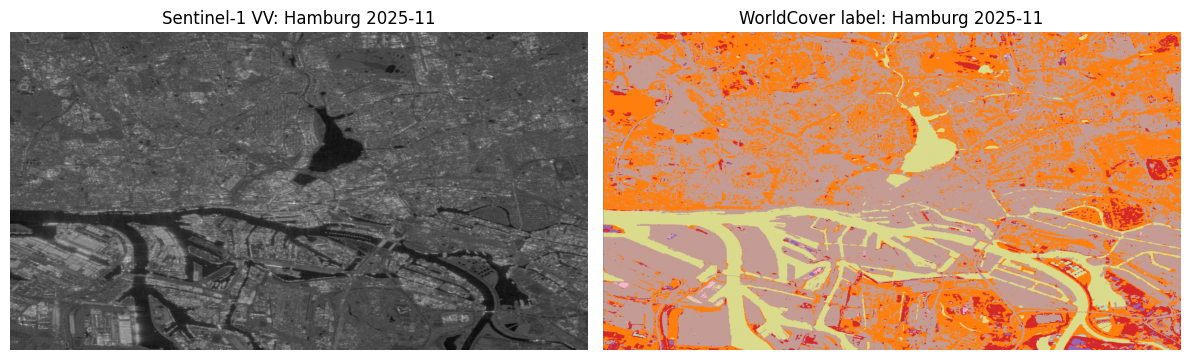

In [16]:
import rasterio
import matplotlib.pyplot as plt

sample_tag = new_metadata_records[0]
s1_path = f"{DRIVE_FOLDER}/{sample_tag['s1_file']}"
wc_path = f"{DRIVE_FOLDER}/{sample_tag['wc_file']}"

with rasterio.open(s1_path) as src:
    s1_data = src.read(1)

with rasterio.open(wc_path) as src:
    wc_data = src.read(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(s1_data, cmap='gray')
axes[0].set_title(f"Sentinel-1 VV: {sample_tag['city']} {sample_tag['year']}-{sample_tag['month']:02d}")
axes[0].axis('off')

axes[1].imshow(wc_data, cmap='tab20')
axes[1].set_title(f"WorldCover label: {sample_tag['city']} {sample_tag['year']}-{sample_tag['month']:02d}")
axes[1].axis('off')

plt.tight_layout()
plt.show()